# TP3 (Big) — Classification d'images : Malaysia Food (Custom CNN vs ResNet-50)

**Auteur :** Dalil NAAMNA — **Identifiant :** 24 — **Date :** 18/11/2026
**Notebook d'origine :** https://www.kaggle.com/code/ragavendransara/23004926-midsem
**Données :** Malaysia Food 11 (Kaggle, 11 classes × 1 000 images, ≈ 1,5 Go)

**Pipeline :** `Data` → `EDA` → `Prétraitement` → `Transformation` → `ML` → `Éval` → `Déploiement`
PySpark gère l'inventaire, l'EDA et le découpage du dataset. PyTorch entraîne les modèles.

## Contribution

**Le notebook est-il correct ?** Oui. Il s'exécute de bout en bout sur Kaggle (GPU, PySpark 4.0.4, Java 21). Toutes les cellules de code ont une sortie et aucune ne lève d'erreur.

**Problèmes rencontrés dans le notebook d'origine**
- Le dataset Malaysia Food est passé de 6 à 11 classes. Le notebook ne prenait pas en compte les 5 nouvelles (`fish_and_chips`, `fried_rice`, `hamburger`, `mixed_rice`, `popiah`).
- Une image est corrompue (classe `nasi_lemak`) : son ouverture faisait planter le chargement.
- Le notebook ne faisait aucun traitement avec PySpark.

**Modifications apportées**
- Ajout des 5 nouvelles classes à `CLASSES` : on passe à 11 classes, soit 11 000 images.
- Installation de PySpark (et de Java 17+ si besoin) et création d'une session Spark locale.
- **Data (PySpark)** : lecture distribuée des fichiers avec `binaryFile`. On récupère le chemin, la classe, la taille, les dimensions et la validité de chaque image. 10 999 images sont lisibles sur 11 000.
- **EDA (PySpark)** : statistiques par classe (nombre d'images, volume, dimensions moyennes, fichiers illisibles) et distribution des dimensions.
- **Prétraitement (PySpark)** : on filtre les images valides, puis on fait un découpage stratifié 70/15/15 avec une `Window` + `percent_rank`, ordonné par un hash du chemin pour que le découpage soit reproductible. Les `Dataset` PyTorch sont ensuite construits à partir de ce découpage.
- Les images illisibles sont remplacées par une image noire au chargement, ce qui évite qu'une seule image fasse planter l'entraînement.
- **Déploiement** : sauvegarde et rechargement du ResNet-50, et fonction `predict_image()` (prédiction, confiance, latence).
- Étiquetage des sections (`## [Étape]`), commentaires et conclusion.

**Autres informations :** l'entraînement dure 70 à 80 min par modèle sur GPU Kaggle (40 époques). Le chemin `DATA_DIR` suppose que le dataset est ajouté comme *Input* Kaggle.

## [Data]

Import des bibliothèques Python et PyTorch.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import torchvision.transforms as transforms
import torchvision.datasets as datasets

Configuration : chemin du dataset, classes retenues, taille d'image, batch size, graine et device (GPU).

**Mise à jour :** le dataset Malaysia Food a grandi (6 → 11 classes). Ce notebook n'incluait pas les nouvelles classes (`fish_and_chips`, `fried_rice`, `hamburger`, `mixed_rice`, `popiah`), je les ai donc ajoutées à la liste `CLASSES`.

In [2]:
DATA_DIR = "/kaggle/input/datasets/karkengchan/malaysia-food-11"
CLASSES  = ["nasi_lemak", "roti_canai", "laksa", "kaya_toast", "satay", "fried_noodles",
            "fish_and_chips", "fried_rice", "hamburger", "mixed_rice", "popiah"]
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


Installation de PySpark (et de Java 17 si besoin), puis création de la session Spark locale.

In [3]:
import sys
import shutil
import subprocess

# Installation de PySpark si absent
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    import pyspark


def java_major():
    if shutil.which("java") is None:
        return 0
    out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    version = out.split('"')[1] if '"' in out else "0"
    parts = version.split(".")
    return int(parts[1]) if parts[0] == "1" else int(parts[0])


# Spark 4.x nécessite Java 17+
if java_major() < 17:
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, BooleanType

spark = (
    SparkSession.builder
    .appName("MalaysiaFood-Pipeline")
    .master("local[*]")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("PySpark", pyspark.__version__, "| Java", java_major(), "| Spark UI:", spark.sparkContext.uiWebUrl)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 12:53:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark 4.0.4 | Java 21 | Spark UI: http://c23c4cdc5e1a:4040


Lecture distribuée de tous les fichiers images avec Spark (`binaryFile`) : chemin, classe, taille, dimensions et validité de chaque image.

In [4]:
from urllib.parse import unquote
from PIL import Image as PILImage

IMG_EXT_REGEX = r"(?i)\.(jpg|jpeg|png|bmp|webp|tif|tiff)$"

# Lecture distribuée des métadonnées des fichiers (sans charger le contenu binaire)
files_df = (
    spark.read.format("binaryFile")
    .option("recursiveFileLookup", "true")
    .load(DATA_DIR)
    .select("path", "length")
    .filter(F.col("path").rlike(IMG_EXT_REGEX))
)

clean_path = F.udf(lambda p: os.path.normpath(unquote(p[len("file:"):] if p.startswith("file:") else p)))


def image_info(local_path):
    """Lit uniquement l'en-tête de l'image : dimensions + validité du fichier."""
    try:
        with PILImage.open(local_path) as im:
            width, height = im.size
            im.verify()
        return (width, height, True)
    except Exception:
        return (None, None, False)


info_udf = F.udf(image_info, StructType([
    StructField("width", IntegerType()),
    StructField("height", IntegerType()),
    StructField("valid", BooleanType()),
]))

files_df = (
    files_df
    .withColumn("local_path", clean_path("path"))
    .withColumn("label", F.regexp_extract("local_path", r"([^/]+)/[^/]+$", 1))
    .withColumn("info", info_udf("local_path"))
    .select("local_path", "label", "length", "info.width", "info.height", "info.valid")
    .cache()
)

n_total = files_df.count()
n_valid = files_df.filter("valid").count()
example_path = files_df.select("local_path").first()["local_path"] if n_total else None
assert n_valid > 0, f"Aucune image lisible ({n_total} fichiers trouvés). Exemple de chemin : {example_path}"
print(f"Nombre total d'images : {n_total} | lisibles : {n_valid}")
files_df.show(5, truncate=60)

Nombre total d'images : 11000 | lisibles : 10999
+------------------------------------------------------------+-------------+-------+-----+------+-----+
|                                                  local_path|        label| length|width|height|valid|
+------------------------------------------------------------+-------------+-------+-----+------+-----+
|/kaggle/input/datasets/karkengchan/malaysia-food-11/laksa...|        laksa|8892198| 4055|  3280| true|
|/kaggle/input/datasets/karkengchan/malaysia-food-11/nasi_...|   nasi_lemak|6588016| 4000|  2655| true|
|/kaggle/input/datasets/karkengchan/malaysia-food-11/laksa...|        laksa|6511887| 4896|  3264| true|
|/kaggle/input/datasets/karkengchan/malaysia-food-11/fried...|fried_noodles|6293727| 3280|  4928| true|
|/kaggle/input/datasets/karkengchan/malaysia-food-11/roti_...|   roti_canai|6245865| 3456|  2304| true|
+------------------------------------------------------------+-------------+-------+-----+------+-----+
only showing to

## [EDA]

Statistiques par classe calculées avec Spark (nombre d'images, volume, dimensions moyennes, fichiers illisibles) et distributions des dimensions et tailles de fichiers.

         label  n_images  size_mb  avg_width  avg_height  n_invalid
    nasi_lemak      1000    205.8     1027.0       922.0          1
    kaya_toast      1000    152.0      828.0       685.0          0
    roti_canai      1000    189.9      975.0       901.0          0
        popiah      1000    150.0      864.0       767.0          0
         laksa      1000    193.0      991.0       913.0          0
 fried_noodles      1000    170.0      822.0       689.0          0
    mixed_rice      1000    185.5      957.0       858.0          0
         satay      1000    153.6      927.0       829.0          0
fish_and_chips      1000     49.1      500.0       473.0          0
    fried_rice      1000     52.2      495.0       469.0          0
     hamburger      1000     48.8      495.0       466.0          0

Taille totale : 1.51 Go
Images illisibles : 1



Dimensions (pixels) :
           width       height
min    120.00000    90.000000
50%    680.00000   550.000000
mean   807.26957   724.675425
max   7216.00000  6000.000000


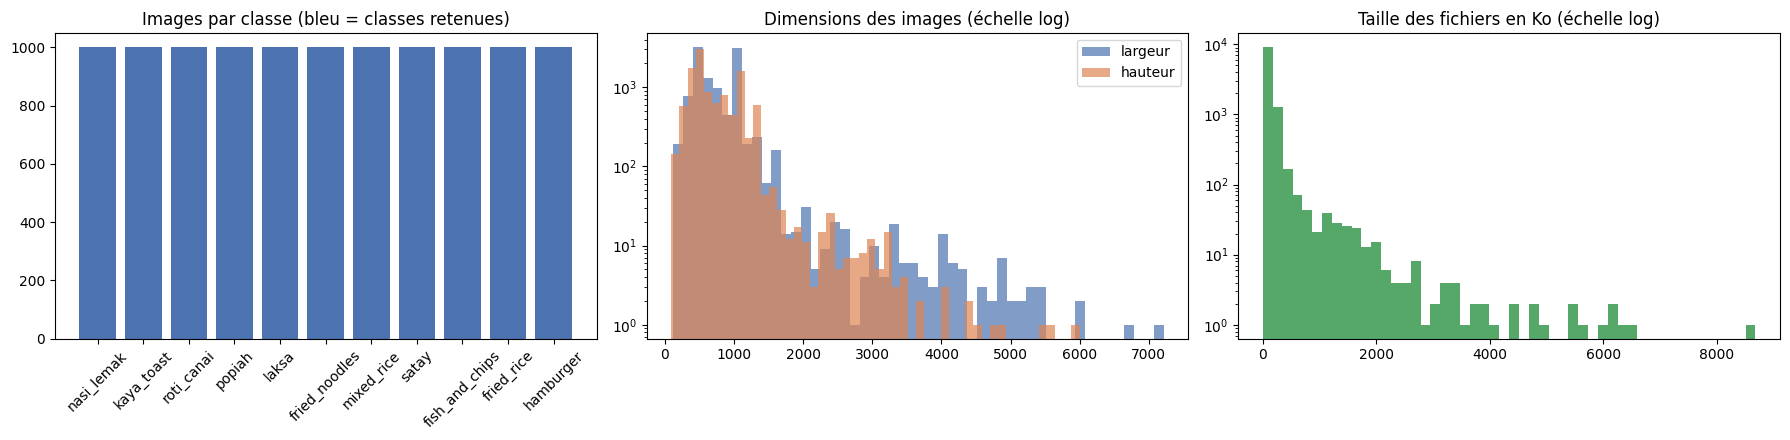

In [5]:
# Statistiques par classe calculées par Spark (sur les 11 classes du dataset complet)
class_stats = (
    files_df.groupBy("label")
    .agg(
        F.count("*").alias("n_images"),
        F.round(F.sum("length") / 1024**2, 1).alias("size_mb"),
        F.round(F.avg("width")).alias("avg_width"),
        F.round(F.avg("height")).alias("avg_height"),
        F.sum(F.when(~F.col("valid"), 1).otherwise(0)).alias("n_invalid"),
    )
    .orderBy(F.desc("n_images"))
    .toPandas()
)
print(class_stats.to_string(index=False))
print(f"\nTaille totale : {class_stats['size_mb'].sum() / 1024:.2f} Go")
print("Images illisibles :", int(class_stats["n_invalid"].sum()))

dims = files_df.filter("valid").select("width", "height").toPandas()
print("\nDimensions (pixels) :")
print(dims.describe().loc[["min", "50%", "mean", "max"]])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
colors = ["#4C72B0" if c in CLASSES else "#BBBBBB" for c in class_stats["label"]]
axes[0].bar(class_stats["label"], class_stats["n_images"], color=colors)
axes[0].set_title("Images par classe (bleu = classes retenues)")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(dims["width"], bins=50, color="#4C72B0", alpha=0.7, label="largeur")
axes[1].hist(dims["height"], bins=50, color="#DD8452", alpha=0.7, label="hauteur")
axes[1].set_yscale("log")
axes[1].set_title("Dimensions des images (échelle log)")
axes[1].legend()
axes[2].hist(files_df.select("length").toPandas()["length"] / 1024, bins=50, color="#55A868")
axes[2].set_yscale("log")
axes[2].set_title("Taille des fichiers en Ko (échelle log)")
plt.tight_layout()
plt.show()

## [Prétraitement]

Filtrage des 11 classes retenues et des images valides, puis découpage stratifié 70 % train / 15 % val / 15 % test avec Spark.

In [6]:
# Filtrage (11 classes retenues + images valides) puis découpage stratifié 70/15/15 avec Spark
# Ordre pseudo-aléatoire basé sur un hash du chemin : découpage identique d'une session à l'autre
w = Window.partitionBy("label").orderBy("rand")
split_df = (
    files_df
    .filter(F.col("label").isin(CLASSES) & F.col("valid"))
    .withColumn("rand", F.xxhash64("local_path", F.lit(SEED)))
    .withColumn("pct", F.percent_rank().over(w))
    .withColumn(
        "split",
        F.when(F.col("pct") < 0.70, "train").when(F.col("pct") < 0.85, "val").otherwise("test"),
    )
    .select("local_path", "label", "split")
    .cache()
)

split_df.groupBy("split").pivot("label", CLASSES).count().orderBy("split").show()

# Seuls les chemins (quelques Ko) sont rapatriés côté driver pour PyTorch
split_pdf = split_df.toPandas()
print(split_pdf["split"].value_counts())

+-----+----------+----------+-----+----------+-----+-------------+--------------+----------+---------+----------+------+
|split|nasi_lemak|roti_canai|laksa|kaya_toast|satay|fried_noodles|fish_and_chips|fried_rice|hamburger|mixed_rice|popiah|
+-----+----------+----------+-----+----------+-----+-------------+--------------+----------+---------+----------+------+
| test|       150|       150|  150|       150|  150|          150|           150|       150|      150|       150|   150|
|train|       699|       700|  700|       700|  700|          700|           700|       700|      700|       700|   700|
|  val|       150|       150|  150|       150|  150|          150|           150|       150|      150|       150|   150|
+-----+----------+----------+-----+----------+-----+-------------+--------------+----------+---------+----------+------+

split
train    7699
val      1650
test     1650
Name: count, dtype: int64


Construction des datasets PyTorch train / val / test à partir du découpage Spark.

In [7]:
from torch.utils.data import Subset

full_dataset = datasets.ImageFolder(root=DATA_DIR)

# Filter and remap labels
class_to_idx = {cls: full_dataset.class_to_idx[cls] for cls in CLASSES}
idx_to_class = {v: k for k, v in class_to_idx.items()}

# New mapping: original index -> new index
old_to_new = {old_idx: new_idx for new_idx, (cls, old_idx) in enumerate(class_to_idx.items())}
idx_to_class = {i: cls for i, cls in enumerate(CLASSES)}

class FilteredDataset(Dataset):
    def __init__(self, dataset, classes, transform=None):
        self.dataset = dataset
        self.transform = transform
        self.old_to_new = {dataset.class_to_idx[cls]: i for i, cls in enumerate(classes)}
        self.samples = [(path, self.old_to_new[label])
                        for path, label in dataset.samples
                        if label in self.old_to_new]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

train_val_test = FilteredDataset(full_dataset, CLASSES, transform=None)

assert len(split_pdf) > 0, "Le découpage Spark est vide : vérifier DATA_DIR et CLASSES."
print(f"Images dans le découpage Spark : {len(split_pdf)} | images des classes retenues (ImageFolder) : {len(train_val_test)}")

# Correspondance chemin -> indice, pour appliquer le découpage calculé par Spark
path_to_idx = {os.path.normpath(p): i for i, (p, _) in enumerate(train_val_test.samples)}


def indices_for(split_name):
    paths = split_pdf.loc[split_pdf["split"] == split_name, "local_path"]
    missing = [p for p in paths if p not in path_to_idx]
    assert not missing, f"{len(missing)} chemins Spark introuvables, ex : {missing[:3]}"
    return [path_to_idx[p] for p in paths]


train_set = Subset(train_val_test, indices_for("train"))
val_set   = Subset(train_val_test, indices_for("val"))
test_set  = Subset(train_val_test, indices_for("test"))
print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Images dans le découpage Spark : 10999 | images des classes retenues (ImageFolder) : 11000
Train: 7699 | Val: 1650 | Test: 1650


## [Transformation]

Définition des transformations : redimensionnement, normalisation ImageNet et augmentations de données (flip, rotation, couleurs, crop) pour le train uniquement.

In [11]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

Application des transformations à chaque sous-ensemble (images corrompues remplacées par une image noire).

In [12]:
class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        try:
            img = Image.open(path).convert("RGB")
        except Exception:
            img = Image.new("RGB", (224, 224), (0, 0, 0))  # black placeholder
        return self.transform(img), label

train_set = TransformSubset(train_set, train_transforms)
val_set   = TransformSubset(val_set,   val_test_transforms)
test_set  = TransformSubset(test_set,  val_test_transforms)

Création des `DataLoader` PyTorch (batchs de 32 images).

In [13]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Batches — Train: 241 | Val: 52 | Test: 52


Visualisation d'un batch d'entraînement après augmentation.

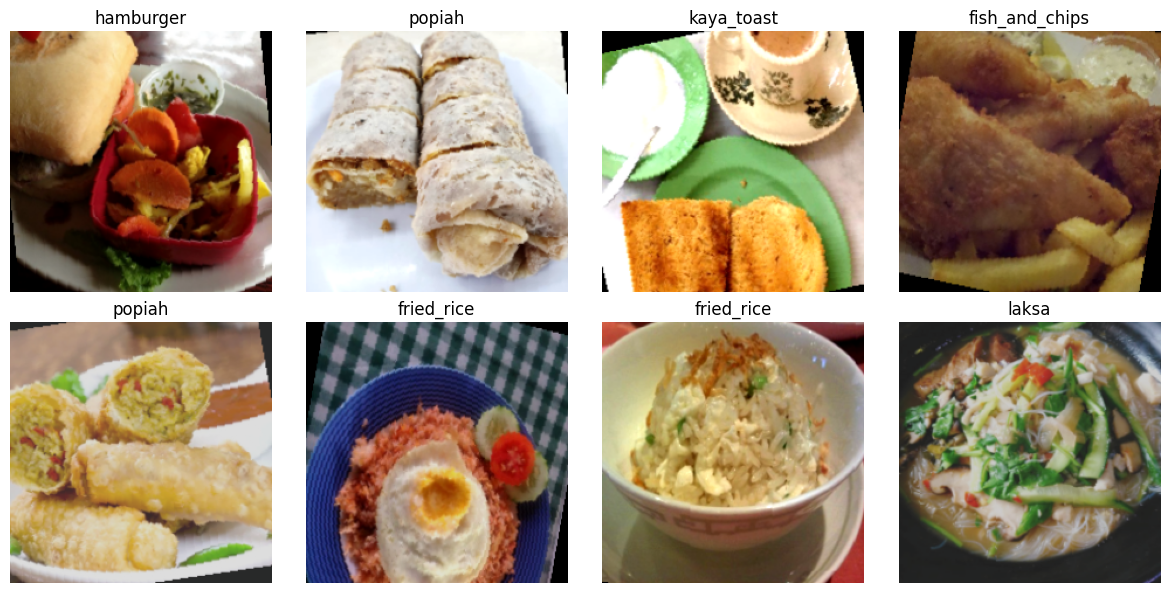

In [14]:
imgs, labels = next(iter(train_loader))

mean = torch.tensor([0.485, 0.456, 0.406])
std  = torch.tensor([0.229, 0.224, 0.225])

# Use idx_to_class instead of CLASSES[label]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    img = imgs[i] * std[:, None, None] + mean[:, None, None]
    img = img.permute(1, 2, 0).numpy().clip(0, 1)
    ax.imshow(img)
    ax.set_title(idx_to_class[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

## [ML]

Définition d'un CNN personnalisé à 5 blocs convolutifs avec Global Average Pooling.

In [15]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(CustomCNN, self).__init__()

        # Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 224 -> 112
        )
        # Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 112 -> 56
        )
        # Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 56 -> 28
        )
        # Block 4
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 28 -> 14
        )
        # Block 5 (new)
        self.block5 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 14 -> 7
        )

        # Global Average Pooling instead of flat FC
        self.gap = nn.AdaptiveAvgPool2d(1)  # 7x7 -> 1x1

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.gap(x)
        x = self.classifier(x)
        return x

model_cnn = CustomCNN(num_classes=NUM_CLASSES).to(device)
print(model_cnn)

CustomCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Ba

Nombre de paramètres, forme des sorties de chaque bloc et champ réceptif.

In [16]:
# Parameter count
total_params = sum(p.numel() for p in model_cnn.parameters())
trainable_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

x = torch.zeros(1, 3, 224, 224).to(device)
for name, block in [("block1", model_cnn.block1),
                    ("block2", model_cnn.block2),
                    ("block3", model_cnn.block3),
                    ("block4", model_cnn.block4),
                    ("block5", model_cnn.block5)]:
    x = block(x)
    print(f"  {name}: {tuple(x.shape)}")

# Receptive field per block (manual calculation for 3x3 convs + 2x2 maxpool)
print("\nReceptive field per block:")
rf = 1
stride = 1
for i, (k, s) in enumerate([(3,1),(2,2),(3,1),(2,2),(3,1),(2,2),(3,1),(2,2),(3,1),(2,2)], 1):
    rf = rf + (k - 1) * stride
    stride *= s
    if i % 2 == 0:
        print(f"  After block {i//2}: RF = {rf}px")

Total parameters:     1,704,715
Trainable parameters: 1,704,715
  block1: (1, 32, 112, 112)
  block2: (1, 64, 56, 56)
  block3: (1, 128, 28, 28)
  block4: (1, 256, 14, 14)
  block5: (1, 512, 7, 7)

Receptive field per block:
  After block 1: RF = 4px
  After block 2: RF = 10px
  After block 3: RF = 22px
  After block 4: RF = 46px
  After block 5: RF = 94px


Entraînement du CNN personnalisé (Adam, StepLR, 40 époques) avec suivi de la loss et de l'accuracy en validation.

In [17]:
criterion = nn.CrossEntropyLoss()

NUM_EPOCHS = 40
optimizer = optim.Adam(model_cnn.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.5)

cnn_train_losses, cnn_val_losses = [], []
cnn_train_accs,   cnn_val_accs   = [], []

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    # --- Train ---
    model_cnn.train()
    running_loss, correct, total = 0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_cnn(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total

    # --- Validate ---
    model_cnn.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_cnn(imgs)
            loss = criterion(outputs, labels)
            val_loss    += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total   += labels.size(0)

    val_loss = val_loss / len(val_loader)
    val_acc  = val_correct / val_total

    cnn_train_losses.append(train_loss)
    cnn_val_losses.append(val_loss)
    cnn_train_accs.append(train_acc)
    cnn_val_accs.append(val_acc)

    scheduler.step()
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

cnn_train_time = time.time() - start_time
print(f"\nTraining time: {cnn_train_time:.1f}s")

Epoch 01/40 | Train Loss: 2.1141 Acc: 0.2477 | Val Loss: 2.3565 Acc: 0.2279
Epoch 02/40 | Train Loss: 1.9032 Acc: 0.3255 | Val Loss: 1.7148 Acc: 0.3776
Epoch 03/40 | Train Loss: 1.7884 Acc: 0.3676 | Val Loss: 2.3077 Acc: 0.2467
Epoch 04/40 | Train Loss: 1.7001 Acc: 0.3997 | Val Loss: 1.9704 Acc: 0.3230
Epoch 05/40 | Train Loss: 1.6342 Acc: 0.4263 | Val Loss: 1.6639 Acc: 0.4145
Epoch 06/40 | Train Loss: 1.5613 Acc: 0.4537 | Val Loss: 1.6031 Acc: 0.4582
Epoch 07/40 | Train Loss: 1.5100 Acc: 0.4742 | Val Loss: 1.6015 Acc: 0.4539
Epoch 08/40 | Train Loss: 1.3786 Acc: 0.5219 | Val Loss: 1.3541 Acc: 0.5055
Epoch 09/40 | Train Loss: 1.3256 Acc: 0.5477 | Val Loss: 1.2285 Acc: 0.5697
Epoch 10/40 | Train Loss: 1.2794 Acc: 0.5599 | Val Loss: 1.8287 Acc: 0.4376
Epoch 11/40 | Train Loss: 1.2612 Acc: 0.5683 | Val Loss: 1.2690 Acc: 0.5709
Epoch 12/40 | Train Loss: 1.2179 Acc: 0.5841 | Val Loss: 1.3058 Acc: 0.5442
Epoch 13/40 | Train Loss: 1.2009 Acc: 0.5962 | Val Loss: 1.1238 Acc: 0.6000
Epoch 14/40 

Courbes d'apprentissage du CNN personnalisé.

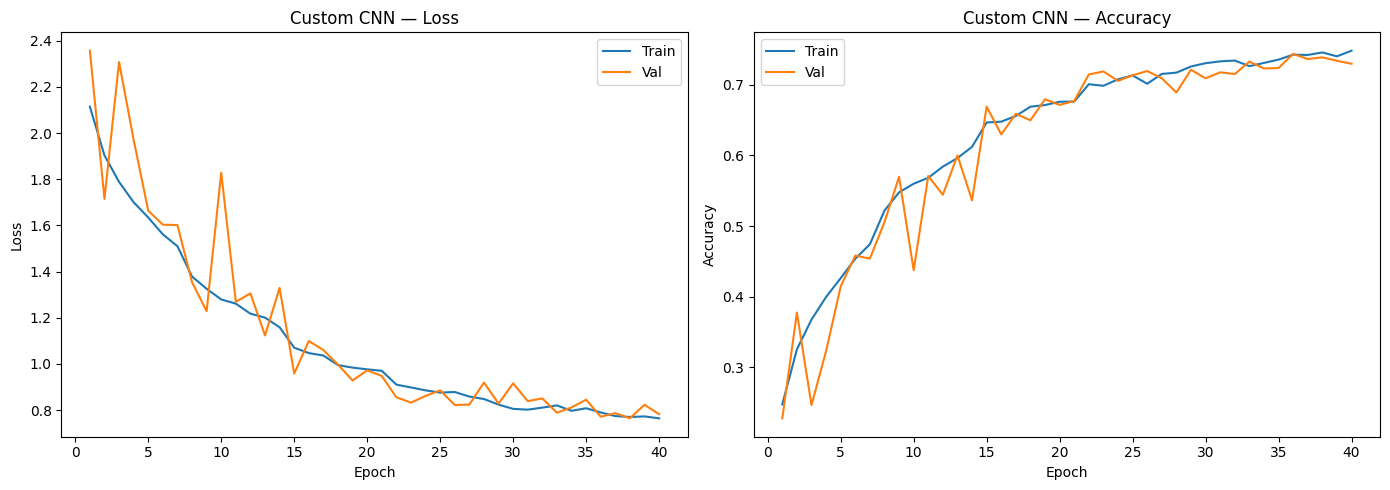

In [18]:
epochs = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs, cnn_train_losses, label="Train")
ax1.plot(epochs, cnn_val_losses,   label="Val")
ax1.set_title("Custom CNN — Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epochs, cnn_train_accs, label="Train")
ax2.plot(epochs, cnn_val_accs,   label="Val")
ax2.set_title("Custom CNN — Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
plt.savefig("cnn_learning_curves.png", dpi=150)
plt.show()

Transfer learning : ResNet-50 pré-entraîné sur ImageNet, seul le dernier bloc (`layer4`) et la nouvelle tête sont entraînés.

In [19]:
import torchvision.models as models

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

for param in resnet.parameters():
    param.requires_grad = False

for param in resnet.layer4.parameters():
    param.requires_grad = True

resnet.fc = nn.Sequential(
    nn.Linear(resnet.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, NUM_CLASSES)
)

resnet = resnet.to(device)

trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
total     = sum(p.numel() for p in resnet.parameters())
print(f"Trainable: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 164MB/s] 


Trainable: 15,492,107 / 24,035,403


Fine-tuning du ResNet-50 (40 époques).

In [20]:
criterion_res = nn.CrossEntropyLoss()
optimizer_res = optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-4)
scheduler_res = optim.lr_scheduler.StepLR(optimizer_res, step_size=5, gamma=0.5)

res_train_losses, res_val_losses = [], []
res_train_accs,   res_val_accs   = [], []

start_res = time.time()

for epoch in range(NUM_EPOCHS):
    resnet.train()
    running_loss, correct, total = 0, 0, 0
    for batch_idx, (imgs, labels) in enumerate(train_loader):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_res.zero_grad()
        outputs = resnet(imgs)
        loss = criterion_res(outputs, labels)
        loss.backward()
        optimizer_res.step()
        running_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
        if (batch_idx + 1) % 20 == 0:
            print(f"  Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}")

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total

    resnet.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = resnet(imgs)
            loss = criterion_res(outputs, labels)
            val_loss    += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total   += labels.size(0)

    val_loss = val_loss / len(val_loader)
    val_acc  = val_correct / val_total

    res_train_losses.append(train_loss)
    res_val_losses.append(val_loss)
    res_train_accs.append(train_acc)
    res_val_accs.append(val_acc)

    scheduler_res.step()
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

res_train_time = time.time() - start_res
print(f"\nResNet training time: {res_train_time:.1f}s")

  Epoch 1 | Batch 20/241 | Loss: 1.9059
  Epoch 1 | Batch 40/241 | Loss: 1.4347
  Epoch 1 | Batch 60/241 | Loss: 0.7387
  Epoch 1 | Batch 80/241 | Loss: 0.8735
  Epoch 1 | Batch 100/241 | Loss: 0.5817
  Epoch 1 | Batch 120/241 | Loss: 0.5539
  Epoch 1 | Batch 140/241 | Loss: 0.4272
  Epoch 1 | Batch 160/241 | Loss: 0.6165
  Epoch 1 | Batch 180/241 | Loss: 0.6231
  Epoch 1 | Batch 200/241 | Loss: 0.7129
  Epoch 1 | Batch 220/241 | Loss: 0.5334
  Epoch 1 | Batch 240/241 | Loss: 0.5281
Epoch 01/40 | Train Loss: 0.9168 Acc: 0.7245 | Val Loss: 0.4701 Acc: 0.8588
  Epoch 2 | Batch 20/241 | Loss: 0.4862
  Epoch 2 | Batch 40/241 | Loss: 0.5159
  Epoch 2 | Batch 60/241 | Loss: 0.4022
  Epoch 2 | Batch 80/241 | Loss: 0.4675
  Epoch 2 | Batch 100/241 | Loss: 0.5066
  Epoch 2 | Batch 120/241 | Loss: 0.4437
  Epoch 2 | Batch 140/241 | Loss: 0.3934
  Epoch 2 | Batch 160/241 | Loss: 0.5216
  Epoch 2 | Batch 180/241 | Loss: 0.3149
  Epoch 2 | Batch 200/241 | Loss: 0.5691
  Epoch 2 | Batch 220/241 | Lo

Comparaison des courbes de validation des deux modèles.

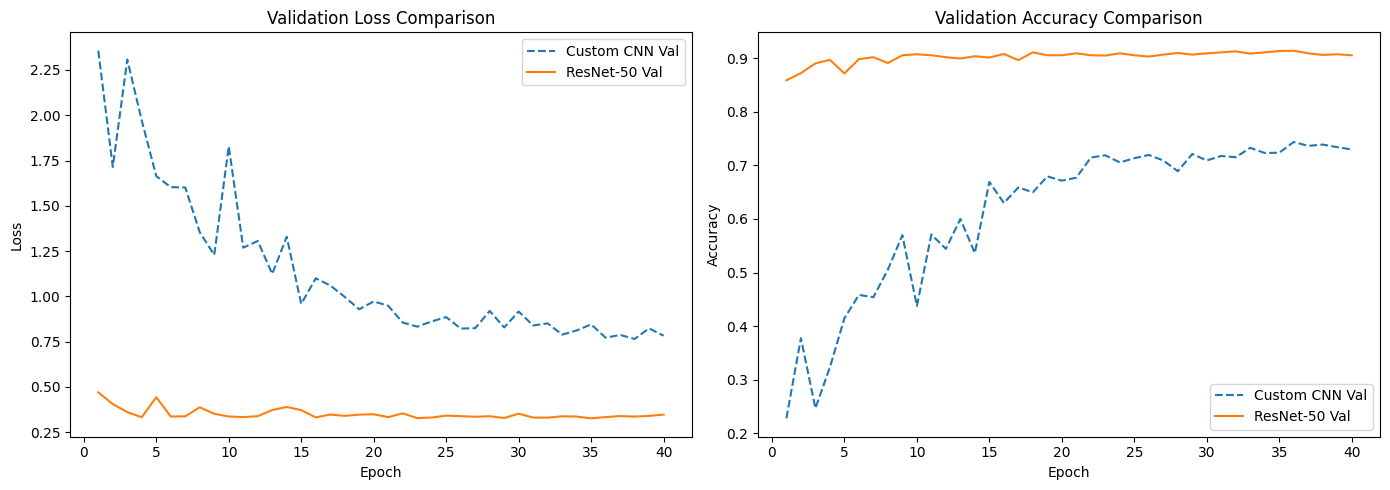

In [21]:
epochs = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs, cnn_val_losses, label="Custom CNN Val", linestyle="--")
ax1.plot(epochs, res_val_losses, label="ResNet-50 Val",  linestyle="-")
ax1.set_title("Validation Loss Comparison")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()

ax2.plot(epochs, cnn_val_accs, label="Custom CNN Val", linestyle="--")
ax2.plot(epochs, res_val_accs, label="ResNet-50 Val",  linestyle="-")
ax2.set_title("Validation Accuracy Comparison")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend()

plt.tight_layout()
plt.savefig("comparison_curves.png", dpi=150)
plt.show()

Tableau récapitulatif : meilleure accuracy de validation, temps d'entraînement et meilleure époque.

In [22]:
def best_epoch(accs): return accs.index(max(accs)) + 1

print(f"{'Model':<15} {'Best Val Acc':>12} {'Train Time':>12} {'Best Epoch':>11}")
print("-" * 55)
print(f"{'Custom CNN':<15} {max(cnn_val_accs):>12.4f} {cnn_train_time:>10.1f}s {best_epoch(cnn_val_accs):>11}")
print(f"{'ResNet-50':<15} {max(res_val_accs):>12.4f} {res_train_time:>10.1f}s {best_epoch(res_val_accs):>11}")

Model           Best Val Acc   Train Time  Best Epoch
-------------------------------------------------------
Custom CNN            0.7436     4776.6s          36
ResNet-50             0.9139     4299.4s          36


## [Éval]

Prédictions du CNN personnalisé sur le jeu de test et accuracy globale.

In [23]:
model_cnn.eval()
all_preds, all_labels, all_paths = [], [], []

with torch.no_grad():
    for idx in range(len(test_set)):
        path, label = test_set.subset.dataset.samples[test_set.subset.indices[idx]]
        img, label_tensor = test_set[idx]
        output = model_cnn(img.unsqueeze(0).to(device))
        pred = output.argmax(1).item()
        all_preds.append(pred)
        all_labels.append(label_tensor)
        all_paths.append(path)

misclassified = [(all_paths[i], all_labels[i], all_preds[i])
                 for i in range(len(all_preds))
                 if all_preds[i] != all_labels[i]]

print(f"Total test samples: {len(test_set)}")
print(f"Misclassified: {len(misclassified)}")
print(f"Test Accuracy: {(1 - len(misclassified)/len(test_set)):.4f}")

Total test samples: 1650
Misclassified: 401
Test Accuracy: 0.7570


Affichage de 10 images mal classées par le CNN.

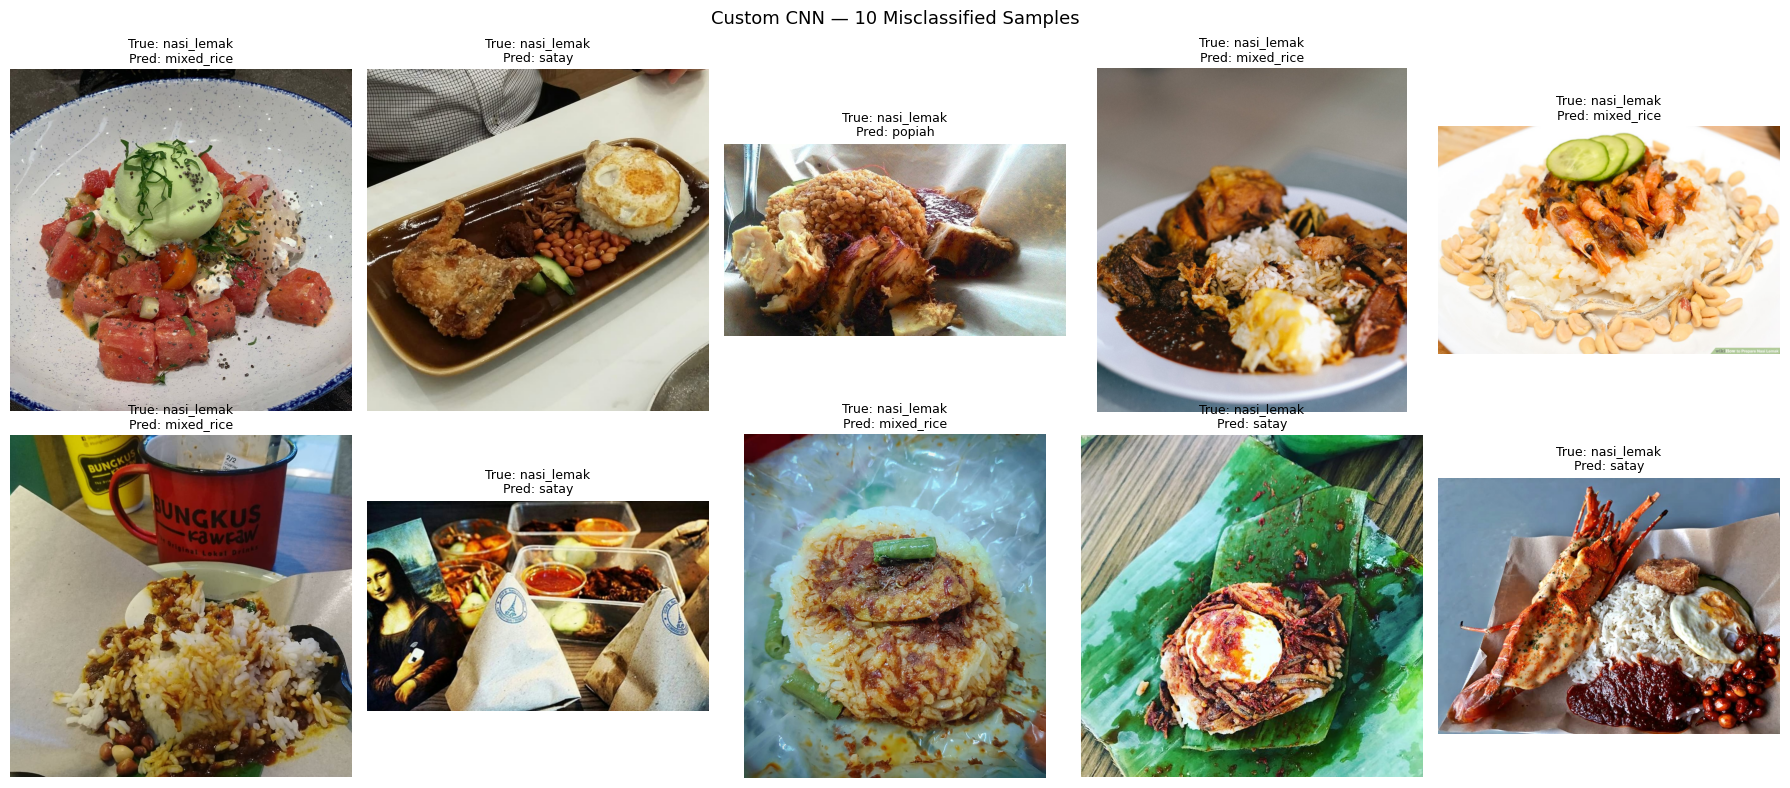

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, ax in enumerate(axes.flat):
    path, true_label, pred_label = misclassified[i]
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"True: {CLASSES[true_label]}\nPred: {CLASSES[pred_label]}", fontsize=9)
    ax.axis("off")

plt.suptitle("Custom CNN — 10 Misclassified Samples", fontsize=13)
plt.tight_layout()
plt.savefig("misclassified.png", dpi=150)
plt.show()

Matrice de confusion du CNN sur le jeu de test.

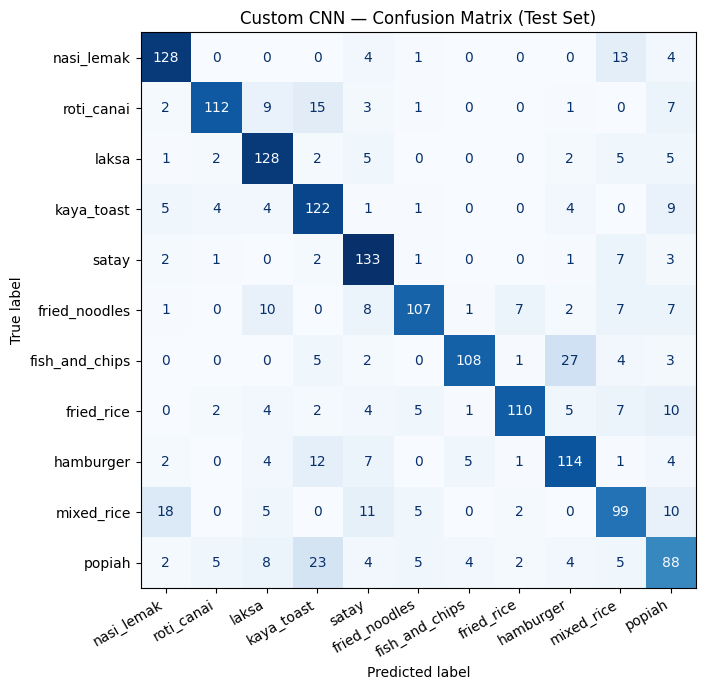

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, colorbar=False, cmap="Blues")
plt.xticks(rotation=30, ha="right")
plt.title("Custom CNN — Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Accuracy par classe du CNN.

In [26]:
print(f"{'Class':<15} {'Correct':>8} {'Total':>8} {'Accuracy':>10}")
print("-" * 45)
for i, cls in enumerate(CLASSES):
    cls_indices = [j for j, l in enumerate(all_labels) if l == i]
    cls_correct = sum(1 for j in cls_indices if all_preds[j] == i)
    print(f"{cls:<15} {cls_correct:>8} {len(cls_indices):>8} {cls_correct/len(cls_indices):>10.4f}")

Class            Correct    Total   Accuracy
---------------------------------------------
nasi_lemak           128      150     0.8533
roti_canai           112      150     0.7467
laksa                128      150     0.8533
kaya_toast           122      150     0.8133
satay                133      150     0.8867
fried_noodles        107      150     0.7133
fish_and_chips       108      150     0.7200
fried_rice           110      150     0.7333
hamburger            114      150     0.7600
mixed_rice            99      150     0.6600
popiah                88      150     0.5867


Matrice de confusion et accuracy par classe du ResNet-50 sur le jeu de test.

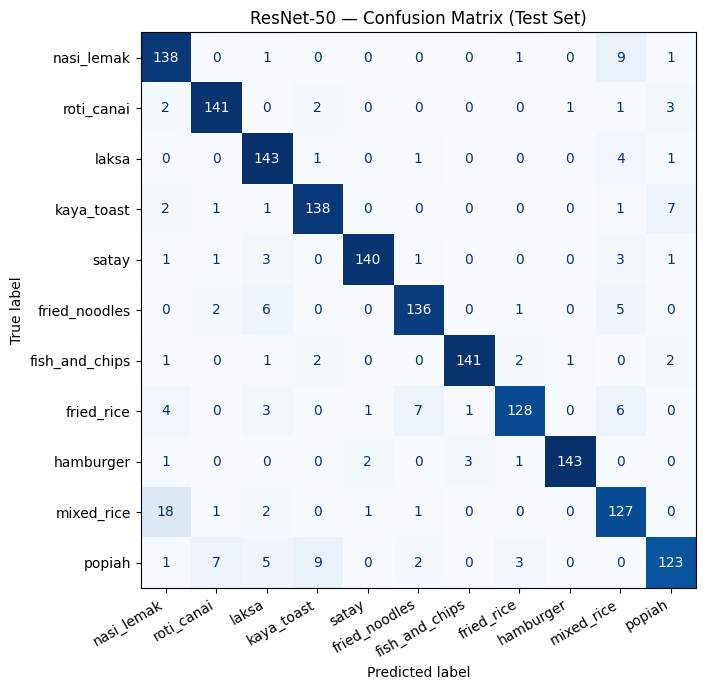


Class            Correct    Total   Accuracy
---------------------------------------------
nasi_lemak           138      150     0.9200
roti_canai           141      150     0.9400
laksa                143      150     0.9533
kaya_toast           138      150     0.9200
satay                140      150     0.9333
fried_noodles        136      150     0.9067
fish_and_chips       141      150     0.9400
fried_rice           128      150     0.8533
hamburger            143      150     0.9533
mixed_rice           127      150     0.8467
popiah               123      150     0.8200


In [27]:
resnet.eval()
res_preds, res_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = resnet(imgs)
        res_preds.extend(outputs.argmax(1).cpu().tolist())
        res_labels.extend(labels.tolist())

cm_res = confusion_matrix(res_labels, res_preds)
disp_res = ConfusionMatrixDisplay(confusion_matrix=cm_res, display_labels=CLASSES)

fig, ax = plt.subplots(figsize=(9, 7))
disp_res.plot(ax=ax, colorbar=False, cmap="Blues")
plt.xticks(rotation=30, ha="right")
plt.title("ResNet-50 — Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("resnet_confusion_matrix.png", dpi=150)
plt.show()

print(f"\n{'Class':<15} {'Correct':>8} {'Total':>8} {'Accuracy':>10}")
print("-" * 45)
for i, cls in enumerate(CLASSES):
    cls_indices = [j for j, l in enumerate(res_labels) if l == i]
    cls_correct = sum(1 for j in cls_indices if res_preds[j] == i)
    print(f"{cls:<15} {cls_correct:>8} {len(cls_indices):>8} {cls_correct/len(cls_indices):>10.4f}")
    

Époque à laquelle chaque modèle atteint 80 % d'accuracy en validation (vitesse de convergence).

In [28]:
# First epoch where val acc exceeds 80%
cnn_80 = next((i+1 for i, a in enumerate(cnn_val_accs) if a >= 0.80), "Never")
res_80 = next((i+1 for i, a in enumerate(res_val_accs) if a >= 0.80), "Never")
print(f"Custom CNN reached 80% val acc at epoch: {cnn_80}")
print(f"ResNet-50 reached 80% val acc at epoch:  {res_80}")

Custom CNN reached 80% val acc at epoch: Never
ResNet-50 reached 80% val acc at epoch:  1


Comparaison des accuracies de test des deux modèles.

In [29]:
# CNN test accuracy (already have from misclassified cell)
cnn_test_acc = 1 - len(misclassified)/len(test_set)

# ResNet test accuracy
res_correct = sum(1 for p, l in zip(res_preds, res_labels) if p == l)
res_test_acc = res_correct / len(res_labels)

print(f"Custom CNN Test Accuracy: {cnn_test_acc:.4f}")
print(f"ResNet-50  Test Accuracy: {res_test_acc:.4f}")

Custom CNN Test Accuracy: 0.7570
ResNet-50  Test Accuracy: 0.9079


Paires de classes les plus confondues par le CNN.

In [30]:
print("Top confused pairs (Custom CNN):")
from collections import defaultdict
confusion_pairs = defaultdict(int)
for true, pred in zip(all_labels, all_preds):
    if true != pred:
        confusion_pairs[(CLASSES[true], CLASSES[pred])] += 1

for pair, count in sorted(confusion_pairs.items(), key=lambda x: -x[1])[:5]:
    print(f"  True: {pair[0]:<15} Pred: {pair[1]:<15} Count: {count}")

Top confused pairs (Custom CNN):
  True: fish_and_chips  Pred: hamburger       Count: 27
  True: popiah          Pred: kaya_toast      Count: 23
  True: mixed_rice      Pred: nasi_lemak      Count: 18
  True: roti_canai      Pred: kaya_toast      Count: 15
  True: nasi_lemak      Pred: mixed_rice      Count: 13


Comparaison par classe CNN vs ResNet-50.

In [31]:
# Class-wise comparison table CNN vs ResNet
print(f"{'Class':<15} {'CNN Acc':>10} {'ResNet Acc':>12} {'Diff':>8}")
print("-" * 50)
for i, cls in enumerate(CLASSES):
    cnn_indices = [j for j, l in enumerate(all_labels) if l == i]
    cnn_correct = sum(1 for j in cnn_indices if all_preds[j] == i)
    cnn_acc = cnn_correct / len(cnn_indices)
    
    res_indices = [j for j, l in enumerate(res_labels) if l == i]
    res_correct = sum(1 for j in res_indices if res_preds[j] == i)
    res_acc = res_correct / len(res_indices)
    
    print(f"{cls:<15} {cnn_acc:>10.4f} {res_acc:>12.4f} {res_acc-cnn_acc:>+8.4f}")

print(f"\n{'Overall':<15} {cnn_test_acc:>10.4f} {res_test_acc:>12.4f} {res_test_acc-cnn_test_acc:>+8.4f}")

Class              CNN Acc   ResNet Acc     Diff
--------------------------------------------------
nasi_lemak          0.8533       0.9200  +0.0667
roti_canai          0.7467       0.9400  +0.1933
laksa               0.8533       0.9533  +0.1000
kaya_toast          0.8133       0.9200  +0.1067
satay               0.8867       0.9333  +0.0467
fried_noodles       0.7133       0.9067  +0.1933
fish_and_chips      0.7200       0.9400  +0.2200
fried_rice          0.7333       0.8533  +0.1200
hamburger           0.7600       0.9533  +0.1933
mixed_rice          0.6600       0.8467  +0.1867
popiah              0.5867       0.8200  +0.2333

Overall             0.7570       0.9079  +0.1509


## [Déploiement]

Sauvegarde du meilleur modèle (ResNet-50), rechargement et fonction d'inférence `predict_image()` testée sur des images du jeu de test, puis arrêt de Spark.

In [32]:
MODEL_PATH = "/kaggle/working/resnet50_malaysia_food.pt"

# Sauvegarde du meilleur modèle (ResNet-50) avec les métadonnées nécessaires à l'inférence
torch.save({"state_dict": resnet.state_dict(), "classes": CLASSES, "img_size": IMG_SIZE}, MODEL_PATH)
print(f"Modèle sauvegardé : {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024**2:.1f} Mo)")


def load_model(path=MODEL_PATH):
    ckpt = torch.load(path, map_location=device)
    model = models.resnet50(weights=None)
    model.fc = nn.Sequential(
        nn.Linear(model.fc.in_features, 256), nn.ReLU(), nn.Dropout(0.4), nn.Linear(256, len(ckpt["classes"]))
    )
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval(), ckpt["classes"]


def predict_image(image_path, model, classes):
    """Prédit la classe d'une image : prête à être appelée depuis une API (Flask/FastAPI)."""
    img = Image.open(image_path).convert("RGB")
    x = val_test_transforms(img).unsqueeze(0).to(device)
    start = time.time()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    top = probs.argmax().item()
    return {"image": os.path.basename(image_path), "prediction": classes[top],
            "confidence": round(probs[top].item(), 4), "latency_ms": round((time.time() - start) * 1000, 1)}


deployed_model, deployed_classes = load_model()
for idx in range(5):
    path, label = test_set.subset.dataset.samples[test_set.subset.indices[idx]]
    result = predict_image(path, deployed_model, deployed_classes)
    print(result, "| vrai :", CLASSES[label])

spark.stop()

Modèle sauvegardé : /kaggle/working/resnet50_malaysia_food.pt (92.0 Mo)
{'image': '168.jpg', 'prediction': 'nasi_lemak', 'confidence': 0.9995, 'latency_ms': 96.8} | vrai : nasi_lemak
{'image': '263.jpg', 'prediction': 'nasi_lemak', 'confidence': 0.8411, 'latency_ms': 12.1} | vrai : nasi_lemak
{'image': '782.jpg', 'prediction': 'nasi_lemak', 'confidence': 0.9996, 'latency_ms': 12.1} | vrai : nasi_lemak
{'image': '791.jpg', 'prediction': 'nasi_lemak', 'confidence': 1.0, 'latency_ms': 12.4} | vrai : nasi_lemak
{'image': '680.jpg', 'prediction': 'laksa', 'confidence': 0.5126, 'latency_ms': 13.0} | vrai : nasi_lemak


## Conclusion

- **Données :** PySpark a permis d'inventorier les 11 000 images (≈ 1,5 Go) sans les charger en mémoire, de repérer l'image corrompue et de produire un découpage stratifié reproductible : 7 699 images en train, 1 650 en validation et 1 650 en test, soit 150 images par classe en validation comme en test. Les classes sont équilibrées (1 000 images chacune). En revanche, les nouvelles classes (`fish_and_chips`, `fried_rice`, `hamburger`) ont des images beaucoup plus petites, d'environ 500 px de côté.
- **Modèles :** le ResNet-50 pré-entraîné atteint **90,8 %** d'accuracy en test, contre **75,7 %** pour le CNN entraîné de zéro, soit +15 points. Le transfer learning dépasse 80 % en validation dès la 1re époque, alors que le CNN n'y arrive jamais en 40 époques.
- **Erreurs :** les classes les plus difficiles sont `popiah`, `mixed_rice` et `fried_rice`. Ce sont des plats visuellement hétérogènes ou proches d'autres classes. C'est aussi là que le ResNet apporte le plus de gain (jusqu'à +23 points).
- **Déploiement :** le modèle sauvegardé fait 92 Mo et une prédiction prend environ 12 ms sur GPU. Il est utilisable derrière une API.
- **Pistes :** augmenter la résolution des petites images, dégeler plus de couches du ResNet, ou essayer des architectures plus récentes (EfficientNet, ViT).